# ¿Qué se asocia con el éxito de un indie en Steam? — Modelos de regresión

El análisis exploratorio en SQL (`sql/eda/`) mostró patrones de precio, momento de
lanzamiento, géneros y tags. Muchos podían deberse a **confusión**: por ejemplo, los
juegos lanzados en fin de semana podrían rendir peor porque suelen ser de
desarrolladores sin publisher, y no por el día en sí.

Aquí se estima cada asociación **controlando las demás variables a la vez**.

| Modelo | Variable respuesta | Universo | Qué responde |
|---|---|---|---|
| 1 | log(reseñas + 1) | Todos los indies 2016–2023 | Alcance: precio, momento, características, géneros |
| 2 | log(reseñas + 1) | Indies con tags | Alcance: tags de diseño |
| 3 | % de reseñas positivas | Indies con 50 o más reseñas | Calidad percibida |

**Cómo leer los resultados**
- Modelos 1 y 2: el efecto es el **% de cambio en reseñas** frente a la categoría de
  referencia, con todo lo demás constante.
- Modelo 3: el efecto está en **puntos porcentuales** de valoración positiva.
- Barras = intervalo de confianza del 95 % (errores robustos HC3). Gris = el
  intervalo cruza el cero: no se distingue de "sin efecto".
- **Son asociaciones, no efectos causales.** Ver `docs/decisiones_metodologicas.md`.

In [17]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.analysis.dataset import load_model_dataset
from src.analysis import models as m

pd.set_option("display.float_format", "{:,.2f}".format)
df = load_model_dataset()
print(f"{len(df):,} indies | {df['tiene_tags'].sum():,} con tags | "
      f"{(df['total_reviews'] >= 50).sum():,} con 50 o más reseñas")

50,801 indies | 44,566 con tags | 15,698 con 50 o más reseñas


## Modelo 1 — Alcance (todos los juegos)

Incluye precio, año de lanzamiento (controla que los juegos más antiguos han
tenido más tiempo para acumular reseñas), mes, día de la semana, si es
autopublicado, características de la ficha de la tienda y géneros. **No incluye
tags**, porque los tags solo existen para juegos que ya tuvieron jugadores: serían
en parte una consecuencia del alcance, no una causa.

In [18]:
r1 = m.fit(df, "log_resenas", with_tags=False)
t1 = m.tidy(r1, log_outcome=True)
print(f"n = {int(r1.nobs):,} | R² = {r1.rsquared:.3f}")

n = 50,801 | R² = 0.343


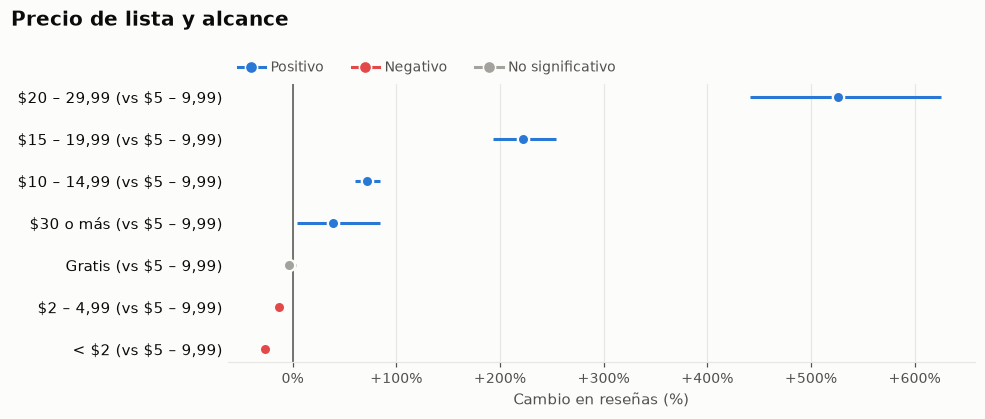

In [19]:
m.show(m.plot_effects(t1, "Precio de lista y alcance", "%", ["Precio"]))

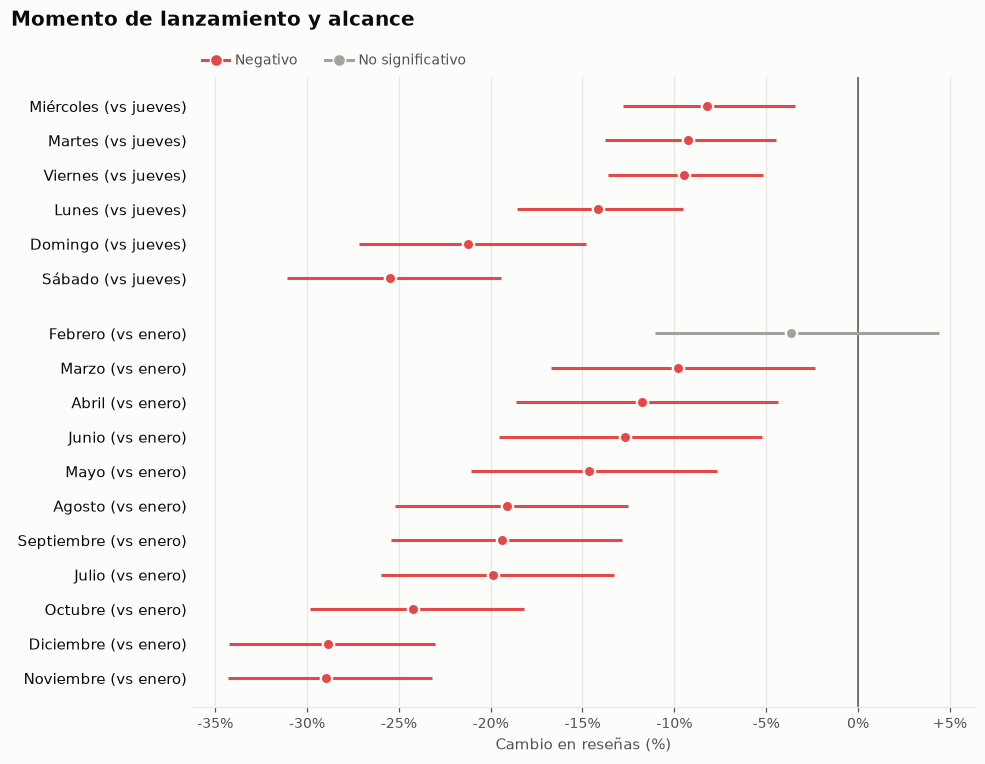

In [20]:
m.show(m.plot_effects(t1, "Momento de lanzamiento y alcance", "%",
                     ["Día de lanzamiento", "Mes de lanzamiento"]))

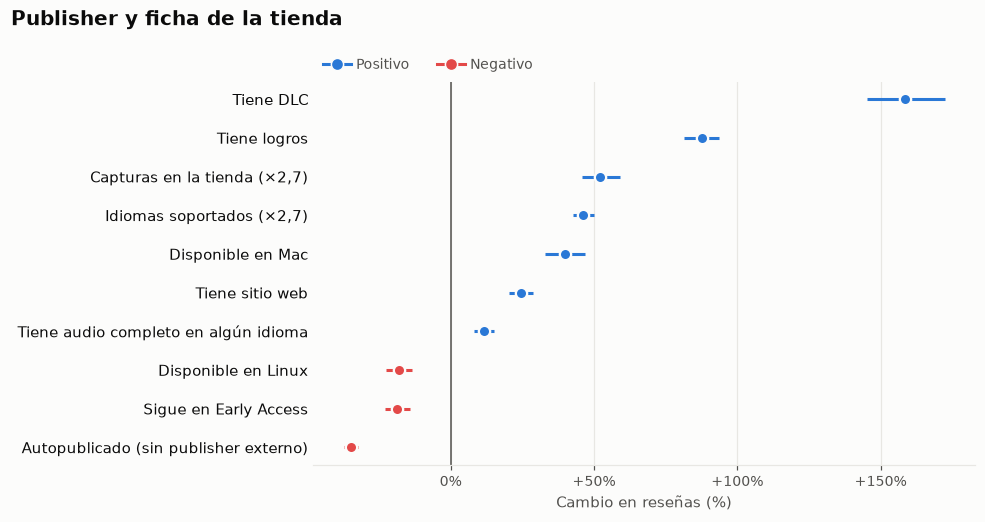

In [21]:
m.show(m.plot_effects(t1, "Publisher y ficha de la tienda", "%", ["Características"]))

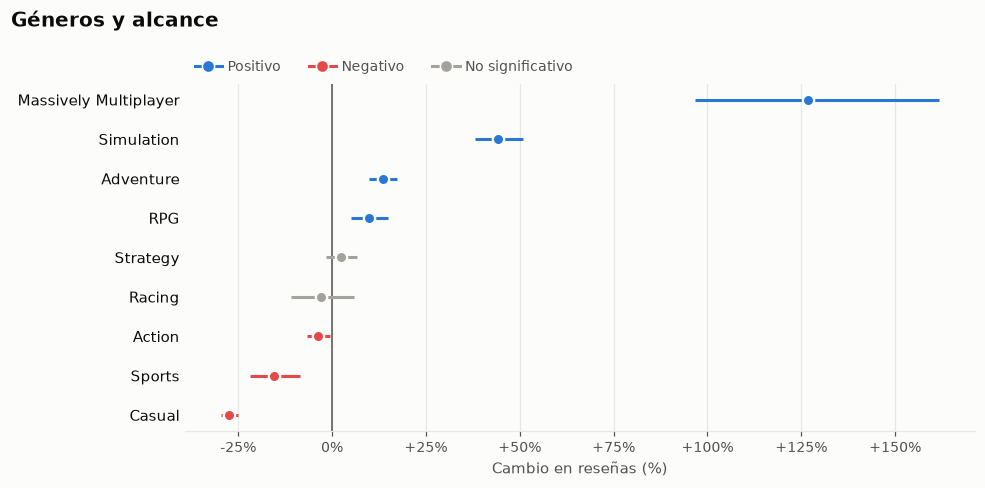

In [22]:
m.show(m.plot_effects(t1, "Géneros y alcance", "%", ["Género"]))

In [23]:
r1b = m.fit(df[df["anio"] <= 2021], "log_resenas", with_tags=False)
t1b = m.tidy(r1b, log_outcome=True)
meses = (t1.loc[t1["grupo"] == "Mes de lanzamiento", ["term", "label", "efecto"]]
           .merge(t1b.loc[t1b["grupo"] == "Mes de lanzamiento", ["term", "efecto", "significativo"]],
                  on="term", suffixes=("_2016_2023", "_2016_2021")))
print(f"n (2016–2021) = {int(r1b.nobs):,}")
meses.drop(columns="term")

n (2016–2021) = 33,665


,label,efecto_2016_2023,efecto_2016_2021,significativo
0,Febrero (vs enero),-3.63,-2.56,False
1,Marzo (vs enero),-9.80,-8.34,False
2,Abril (vs enero),-11.76,-11.51,True
3,Mayo (vs enero),-14.62,-17.05,True
4,Junio (vs enero),-12.68,-16.81,True
5,Julio (vs enero),-19.89,-22.65,True
6,Agosto (vs enero),-19.10,-23.95,True
7,Septiembre (vs enero),-19.40,-26.12,True
8,Octubre (vs enero),-24.21,-29.84,True
9,Noviembre (vs enero),-28.97,-34.06,True


## Modelo 2 — Alcance y tags de diseño (juegos con tags)

Solo se usan **tags de diseño** (cómo es el juego), no de recepción como *Great
Soundtrack* o *Memes*, que los jugadores agregan después de disfrutar el juego.

**Sesgo de selección: estos efectos son conservadores.** Al quedarnos solo con
juegos que tienen tags, ya filtramos por haber tenido jugadores. Eso recorta la
variable respuesta y tiende a *reducir* los efectos estimados hacia cero. En una
prueba con datos sintéticos, un efecto plantado de +0,8 se recuperó como +0,39.
El signo y el orden relativo de los tags son confiables; la magnitud, probablemente
subestimada.

n = 44,566 | R² = 0.436


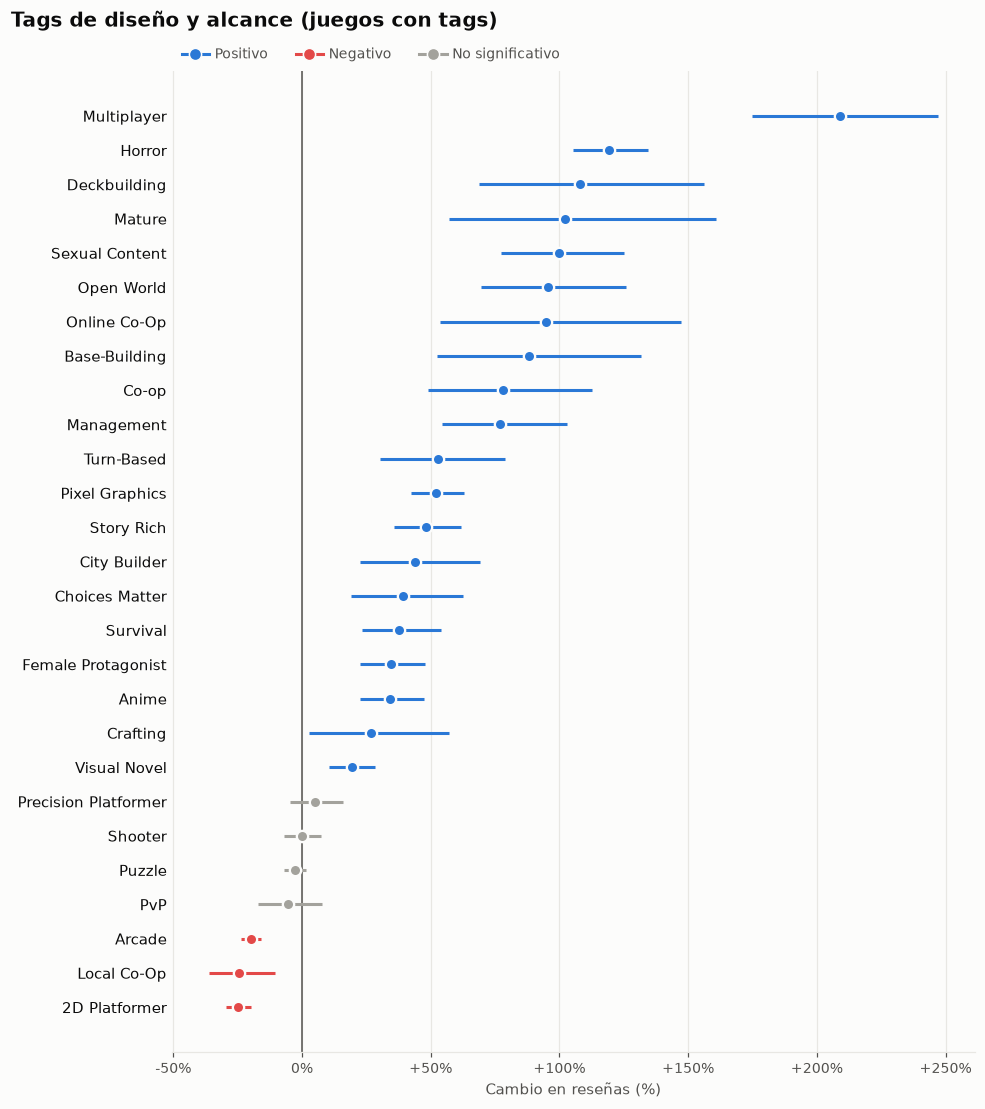

In [24]:
df_tags = df[df["tiene_tags"] == 1]
r2 = m.fit(df_tags, "log_resenas", with_tags=True)
t2 = m.tidy(r2, log_outcome=True)
print(f"n = {int(r2.nobs):,} | R² = {r2.rsquared:.3f}")
m.show(m.plot_effects(t2, "Tags de diseño y alcance (juegos con tags)", "%", ["Tag de diseño"]))

## Modelo 3 — Calidad percibida (juegos con 50 o más reseñas)

La variable respuesta es el % de reseñas positivas. Se limita a juegos con 50 o más
reseñas porque con menos el porcentaje es muy inestable. Esto también implica
condicionar al alcance: los resultados describen la valoración **entre los juegos
que ya consiguieron jugadores**.

n = 15,698 | R² = 0.201


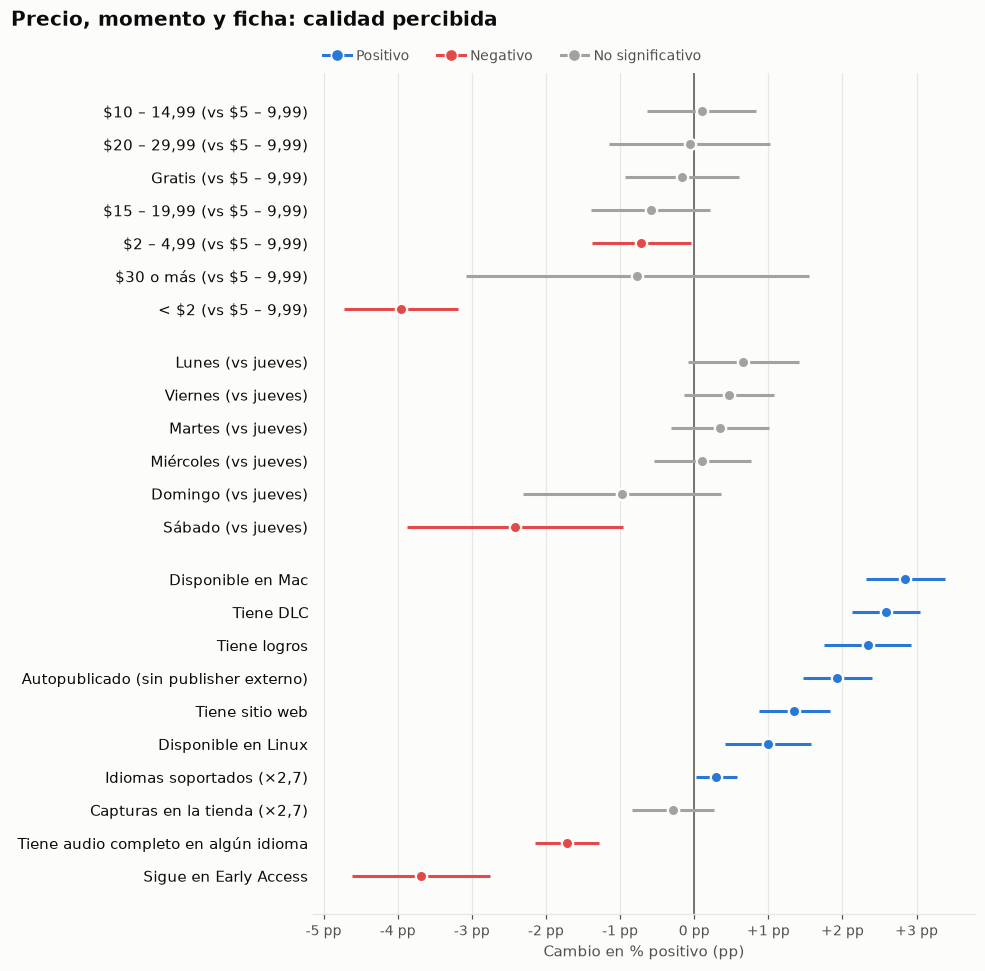

In [25]:
df_q = df[df["total_reviews"] >= 50]
r3 = m.fit(df_q, "pct_positive", with_tags=True)
t3 = m.tidy(r3, log_outcome=False)
print(f"n = {int(r3.nobs):,} | R² = {r3.rsquared:.3f}")
m.show(m.plot_effects(t3, "Precio, momento y ficha: calidad percibida", "pp",
                     ["Precio", "Día de lanzamiento", "Características"]))

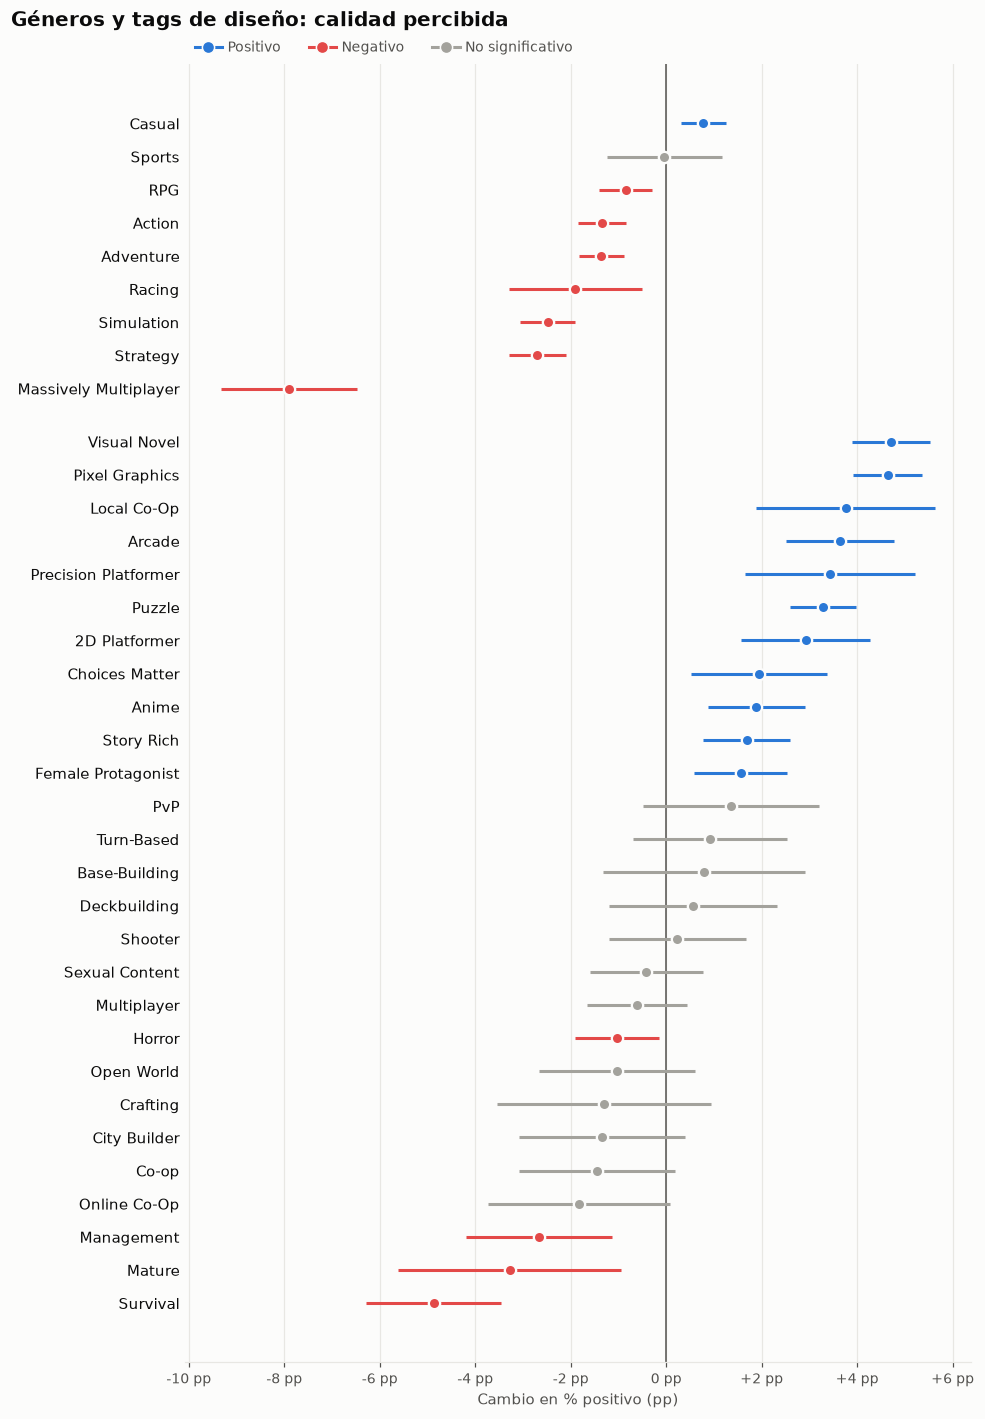

In [26]:
m.show(m.plot_effects(t3, "Géneros y tags de diseño: calidad percibida", "pp",
                     ["Género", "Tag de diseño"]))

## Alcance vs. calidad: ¿qué factores van en direcciones opuestas?

Cruza los modelos de alcance (1 y 2) con el de calidad (3). Los factores que suben
el alcance pero bajan la valoración son candidatos a *éxito comercial polémico*;
los que suben la valoración sin alcance, a *joya oculta*.

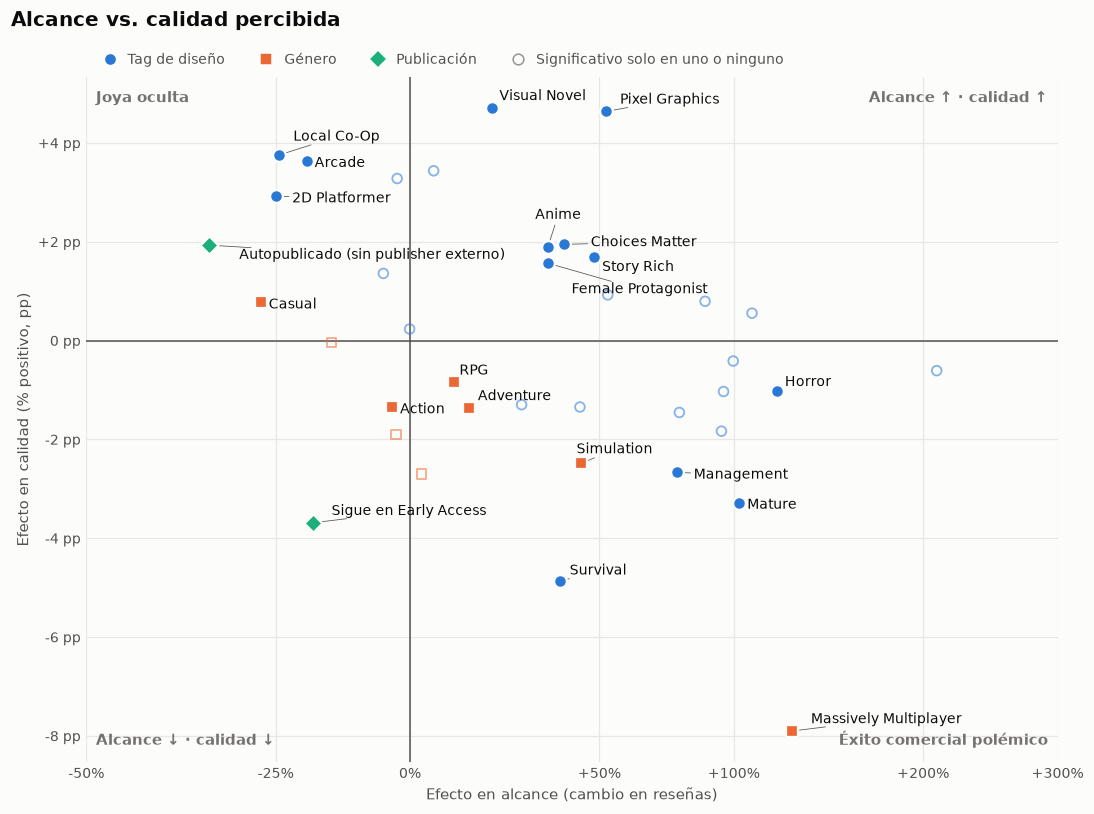

,cuadrante,label,grupo,alcance_%,calidad_pp
33,Alcance ↑ · calidad ↑,Pixel Graphics,Tag de diseño,52.24,4.64
26,Alcance ↑ · calidad ↑,Story Rich,Tag de diseño,48.18,1.69
27,Alcance ↑ · calidad ↑,Choices Matter,Tag de diseño,39.09,1.95
35,Alcance ↑ · calidad ↑,Female Protagonist,Tag de diseño,34.50,1.56
34,Alcance ↑ · calidad ↑,Anime,Tag de diseño,34.32,1.89
25,Alcance ↑ · calidad ↑,Visual Novel,Tag de diseño,19.25,4.71
2,Alcance ↓ · calidad ↓,Action,Género,-3.70,-1.35
1,Alcance ↓ · calidad ↓,Sigue en Early Access,Publicación,-18.79,-3.69
31,Joya oculta,Arcade,Tag de diseño,-19.86,3.64
14,Joya oculta,Local Co-Op,Tag de diseño,-24.40,3.76


In [27]:
cruce = m.reach_quality_table(t1, t2, t3)
m.show(m.plot_reach_quality(cruce, "Alcance vs. calidad percibida"))

# Tabla de apoyo: factores significativos en ambos modelos
(cruce[cruce["sig_ambos"]]
   .assign(cuadrante=lambda d: d.apply(
       lambda r: ("Alcance ↑ · calidad ↑" if r.efecto_alcance > 0 and r.efecto_calidad > 0 else
                  "Éxito comercial polémico" if r.efecto_alcance > 0 else
                  "Joya oculta" if r.efecto_calidad > 0 else
                  "Alcance ↓ · calidad ↓"), axis=1))
   .sort_values(["cuadrante", "efecto_alcance"], ascending=[True, False])
   [["cuadrante", "label", "grupo", "efecto_alcance", "efecto_calidad"]]
   .rename(columns={"efecto_alcance": "alcance_%", "efecto_calidad": "calidad_pp"}))

## Guardar resultados

Las tablas de coeficientes se guardan en `data/processed/` para el dashboard.

In [28]:
out = ROOT / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)
for name, t in [("modelo1_alcance", t1), ("modelo2_alcance_tags", t2), ("modelo3_calidad", t3),
                ("cruce_alcance_calidad", cruce)]:
    t.to_csv(out / f"{name}.csv", index=False)

print("Guardado en", out)

Guardado en /Users/mauriciovazquez/Documents/steam-indie-market/data/processed


## Conclusiones

*Datos: Steam Games Dataset de FronkonGames, actualizado el 2026-11-13. Indies
publicados entre 2016 y 2023, sin software. Todas son asociaciones con controles,
no efectos causales*

**1. El mercado se saturó, pero los lugares de éxito no se redujeron.** Entre 2016 y
2024 los lanzamientos indie se multiplicaron por 4,2, mientras que la cantidad de
juegos que llegan a 100 reseñas se mantuvo entre ~1.200 y 1.600 por año (ver EDA).
La probabilidad de llegar bajó de 47,5 % a 12,5 %, y el 1 % de los indies concentra
el 75 % de las reseñas.

**2. El precio se asocia fuertemente con el alcance, pero no con la calidad.** Frente
a $5–9,99, los indies de $20–29,99 tienen ~6 veces más reseñas. A partir de $5 la
valoración no cambia: los jugadores no castigan pagar más. Los juegos de menos de $2
pierden en las dos dimensiones. El precio probablemente refleja la ambición del
proyecto, y hay causalidad inversa (los juegos que no venden bajan su precio).

**3. El momento de lanzamiento importa, incluso con controles.**
- El **jueves** es el mejor día; sábado (−25 %) y domingo (−21 %) siguen siendo peores
  aunque se controle si el juego tiene publisher.
- **Enero** es el mejor mes y el rendimiento cae hasta noviembre y diciembre (~−30 %).
  La prueba de robustez con cohortes 2016–2021 confirma que es estacionalidad y no
  antigüedad: coincide con la temporada de grandes lanzamientos y ofertas.

**4. Tener publisher se asocia con más alcance; autopublicar, con mejor valoración.**
Los juegos autopublicados tienen un 35 % menos de reseñas pero +1,9 pp de valoración:
el perfil de joya oculta.

**5. Alcance y calidad responden a factores casi opuestos.**
- *Éxito comercial polémico:* juegos sistémicos y de larga duración (Massively
  Multiplayer, Survival, Management, Simulation, Mature) atraen mucho público, pero se
  valoran peor.
- *Joya oculta:* juegos compactos y precisos (2D Platformer, Arcade, Local Co-Op,
  Casual) se valoran mejor, pero llegan a menos jugadores.
- *Alcance y calidad a la vez:* los juegos narrativos y de estilo definido (Visual
  Novel, Story Rich, Choices Matter, Pixel Graphics, Anime, Female Protagonist).

**Límites.** Las reseñas son un proxy de ventas. Las variables de la tienda (precio,
DLC, idiomas, plataformas) describen el estado actual, no el del lanzamiento. Los
efectos de los tags son conservadores por sesgo de selección. La etiqueta "indie" es
autodeclarada. Detalles en `docs/decisiones_metodologicas.md`.